In [0]:
# ==========================================================================================================================================
#                                                 CELL 1 - STEP 1: DATA SELECTION AND INGESTION
# ==========================================================================================================================================
#GOAL: Find the olist files and load them intospark anad print the exact row counts and convert one file into JSON (semi-structured one) and read it.
# Import tools from python library where "os" is for folders/file; "shutil" copies the files; "zipfile" opens .zip archives, "tempfile" is for temporary files
import os
import shutil
import zipfile
import tempfile
# import spark built-in functions, depticting it as F
from pyspark.sql import functions as F

# Location fo olist dataset
BASE = "/Volumes/workspace/default/olist_dataset"
# folder where trasnslated file in JSON format will be saved
TRANSLATION_JSON_DIR = f"{BASE}/product_category_name_translation_json"

print("=" * 70)
print("STEP 1.1 - Checking the volume folder")
print("=" * 70)
#a safety check for confusing errors if folder is not found
if not os.path.isdir(BASE):
    raise FileNotFoundError(
        f"CHECK FAILED: The folder {BASE} does not exist. "
        "Please create the volume 'olist_dataset' in workspace.default and upload the Olist files."
    )
print(f"CHECK PASSED: Folder {BASE} exists.")

print()
print("=" * 70)
print("STEP 1.2 - Unzipping any .zip files found in the volume")
print("=" * 70)
#Make a list of every .zip file in the folder

zip_files = [os.path.join(BASE, f) for f in os.listdir(BASE) if f.lower().endswith(".zip")]
# move on if nozip file is found 
if not zip_files:
    print("No .zip files found. Skipping this step (this is fine if you uploaded CSVs directly).")
# Go through all the zip files one by one
for z in zip_files:
# Create a temporary folder to extract the zip file
    tmp_dir = tempfile.mkdtemp()
# Path for a temporary local copy of the zip file.
    local_zip = os.path.join(tmp_dir, "archive.zip")
    # Copy the zip file to the temporary folder
    shutil.copyfile(z, local_zip)
    # Open the zip file
    with zipfile.ZipFile(local_zip) as zf:
        # Go through all the files in the zip file
        for member in zf.namelist():
            # Skip the __MACOSX folder and any other files that are not CSVs
            if member.lower().endswith(".csv") and "__MACOSX" not in member:
                # Create a new path for the extracted file
                target = os.path.join(BASE, os.path.basename(member))
                # If file already exists, skip it
                if os.path.exists(target):
                    print(f"  Skipped (already exists): {os.path.basename(member)}")
                else:
                    # Extract the csv file to the temporary folder
                    extracted = zf.extract(member, tmp_dir)
                    # Copy the extracted file to the target location
                    shutil.copyfile(extracted, target)
                    print(f"  Extracted: {os.path.basename(member)}")
                    # Delete the temporary folder
    shutil.rmtree(tmp_dir, ignore_errors=True)
print("CHECK PASSED: Unzip step finished.")

print()
print("=" * 70)
print("STEP 1.3 - Locating the CSV files")
print("=" * 70)
# Make a list of all the CSV files in the folder
all_csvs = []
for root, dirs, files in os.walk(BASE):
    for f in files:
        if f.lower().endswith(".csv"):
            all_csvs.append(os.path.join(root, f))

# Helper function:Make a function to find a CSV file by keyword in its name
# This is used to find the files that are not in the same folder as the rest of the files

def find_csv(keyword):
    # Find all the CSV files that contain the keyword in their name
    matches = [p for p in all_csvs if keyword in os.path.basename(p).lower()]

    if not matches:
        raise FileNotFoundError(
            # If no file is found, raise an error
            f"CHECK FAILED: No CSV file with '{keyword}' in its name was found under {BASE}. "
            # If multiple files are found, raise an error
            f"CSV files that were found: {[os.path.basename(p) for p in all_csvs]}"
        )
        # if several matches are found,prefer the closest one to the top folder
    matches.sort(key=lambda p: (p.count("/"), p))
    return matches[0]

# Make a dictionary of file names and their paths
file_keywords = {
    "customers": "customers",
    "geolocation": "geolocation",
    "order_items": "items",
    "order_payments": "payments",
    "order_reviews": "reviews",
    "orders": "orders",
    "products": "products",
    "sellers": "sellers",
    "translation": "translation",
}
# look up the full path of every file in the dictionary
file_paths = {}
for name, kw in file_keywords.items():
    file_paths[name] = find_csv(kw)
    print(f"  Found {name:<15} -> {file_paths[name]}")
print(f"CHECK PASSED: All {len(file_paths)} expected CSV files were found.")

print()
print("=" * 70)
print("STEP 1.4 - Reading all CSV files into Spark")
print("=" * 70)

# Helper function which readds one csv into the spark DataFrame
def read_csv(path, multiline=False):
    reader = (
        spark.read
        # The first row of each file contains the column names.
        .option("header", True)
        # Keep every column as text for now. We convert types on purpose in Step 2,
        # which avoids Spark guessing wrong.
        .option("inferSchema", False)
        # Text containing commas is wrapped in double quotes.
        .option("quote", '"')
         # A doubled quote ("") inside quoted text means a literal quote mark.
        .option("escape", '"')
         # The files are UTF-8 so Portuguese accents are read correctly.
        .option("encoding", "UTF-8")
    )
     # Review comments can span several lines, so that file needs "multiLine" mode.
    if multiline:
        reader = reader.option("multiLine", True)
        # read the file
    df = reader.csv(path)
    # Remove any leading or trailing spaces from column names
    clean_names = [c.replace("\ufeff", "").replace('"', "").strip() for c in df.columns]
    # Return the cleaned DataFrame
    return df.toDF(*clean_names)

# Read all the CSV files into Spark DataFrames
customers_raw   = read_csv(file_paths["customers"])
geolocation_raw = read_csv(file_paths["geolocation"])
items_raw       = read_csv(file_paths["order_items"])
payments_raw    = read_csv(file_paths["order_payments"])
reviews_raw     = read_csv(file_paths["order_reviews"], multiline=True)
orders_raw      = read_csv(file_paths["orders"])
products_raw    = read_csv(file_paths["products"])
sellers_raw     = read_csv(file_paths["sellers"])
translation_raw = read_csv(file_paths["translation"])
print("CHECK PASSED: All 9 CSV files were read into Spark tables.")

print()
print("=" * 70)
print("STEP 1.5 - Exact row counts (CSV)")
print("=" * 70)
# Check the row counts of the CSV files
expected_counts = {
    "customers": 99441, "geolocation": 1000163, "order_items": 112650,
    "order_payments": 103886, "order_reviews": 99224, "orders": 99441,
    "products": 32951, "sellers": 3095, "translation": 71,
}
# To loop, place the all the tables in one dictionary
raw_tables = {
    "customers": customers_raw, "geolocation": geolocation_raw, "order_items": items_raw,
    "order_payments": payments_raw, "order_reviews": reviews_raw, "orders": orders_raw,
    "products": products_raw, "sellers": sellers_raw, "translation": translation_raw,
}
# compare the row counts of the CSV files to the expected counts
for name, df in raw_tables.items():
    n = df.count()
    status = "matches the original Kaggle file" if n == expected_counts[name] else f"differs from the original Kaggle count of {expected_counts[name]:,}"
    print(f"  {name:<15} {n:>10,} rows  ({status})")
print("CHECK PASSED: Row counts printed above.")

print()
print("=" * 70)
print("STEP 1.6 - Converting product_category_name_translation.csv to JSON and reading it back")
print("=" * 70)
# WHY JSON? The project requires a semi-structured format. JSON stores each row
# as self-describing "key: value" pairs, unlike a flat CSV. Writing and reading
# it back shows Spark can handle semi-structured data too.
# coalesce(1) makes Spark write a single output file because the table is tiny 
translation_raw.coalesce(1).write.mode("overwrite").json(TRANSLATION_JSON_DIR)
print(f"  JSON written to folder: {TRANSLATION_JSON_DIR}")
json_files = [f for f in os.listdir(TRANSLATION_JSON_DIR) if f.endswith(".json")]
print(f"  JSON files created: {json_files}")

# Read the JSON back into Spark. Spark works out the column names by itself.
translation_json = spark.read.json(TRANSLATION_JSON_DIR)
json_count = translation_json.count()
print(f"  Rows read back from JSON: {json_count:,}")
print(f"  Columns read back from JSON: {sorted(translation_json.columns)}")
# check if the JSON must contain exactly as many rows as the CSV
if json_count != translation_raw.count():
    raise Exception("CHECK FAILED: The JSON row count does not match the CSV row count.")
print("CHECK PASSED: JSON round trip kept every row (CSV count = JSON count).")
print()
# print the first 5 rows to see the data survived.
print("  First 5 rows read back from JSON:")
print(translation_json.limit(5).toPandas().to_string(index=False))

STEP 1.1 - Checking the volume folder
CHECK PASSED: Folder /Volumes/workspace/default/olist_dataset exists.

STEP 1.2 - Unzipping any .zip files found in the volume
  Skipped (already exists): olist_customers_dataset.csv
  Skipped (already exists): olist_geolocation_dataset.csv
  Skipped (already exists): olist_order_items_dataset.csv
  Skipped (already exists): olist_order_payments_dataset.csv
  Skipped (already exists): olist_order_reviews_dataset.csv
  Skipped (already exists): olist_orders_dataset.csv
  Skipped (already exists): olist_products_dataset.csv
CHECK PASSED: Unzip step finished.

STEP 1.3 - Locating the CSV files
  Found customers       -> /Volumes/workspace/default/olist_dataset/olist_customers_dataset.csv
  Found geolocation     -> /Volumes/workspace/default/olist_dataset/olist_geolocation_dataset.csv
  Found order_items     -> /Volumes/workspace/default/olist_dataset/olist_order_items_dataset.csv
  Found order_payments  -> /Volumes/workspace/default/olist_dataset/olis

In [0]:
# ==========================================================================================================================================
#                                                   CELL 2 - STEP 2: DATA PREPROCESSING
# ==========================================================================================================================================
# Goal: convert text to proper dates/numbers, remove bad rows (canceled orders,
# zero/negative prices), fill missing categories, and print before/after counts.
from pyspark.sql import functions as F

# Timestamp format for the Kaggle data
TS_FMT = "yyyy-MM-dd HH:mm:ss"

# Convert text to timestamp or numbers 
# Because if its not converted the value becomes NULL
def to_ts(df, cols):
    for c in cols:
        df = df.withColumn(c, F.expr(f"try_to_timestamp(`{c}`, '{TS_FMT}')"))
    return df

# Convert text to numbers
def to_num(df, mapping):
    for c, t in mapping.items():
        df = df.withColumn(c, F.expr(f"try_cast(`{c}` AS {t})"))
    return df

# Format numbers as currency
# WITH Thousands of separators and 2 decimal places
def money(x):
    return f"{x:,.2f}"

# Calculate total revenue = sum of "price" colum. Empty result counts as 0
def total_revenue(df):
    value = df.agg(F.sum("price")).collect()[0][0]
    return float(value) if value is not None else 0.0

print("=" * 70)
print("STEP 2.1 - Converting text dates to real timestamps and text numbers to numbers")
print("=" * 70)

# The five date columns in the orders table.
order_date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
orders_ts = to_ts(orders_raw, order_date_cols)
# Convert shipping date in orders table
items_ts = to_ts(items_raw, ["shipping_limit_date"])
# Convert item number, price and freight from text to numbers so we can add them up.
items_num = to_num(items_ts, {"order_item_id": "int", "price": "double", "freight_value": "double"})
# Convert payment columns to numbers.
payments_num = to_num(payments_raw, {"payment_sequential": "int", "payment_installments": "int", "payment_value": "double"})
# Convert the two review date columns, then the review score to a whole number.
reviews_ts = to_ts(reviews_raw, ["review_creation_date", "review_answer_timestamp"])
reviews_num = to_num(reviews_ts, {"review_score": "int"})

# Helper: count how many non-empty (non-NULL) values each listed column has.
def nonnull_counts(df, cols):
    return df.agg(*[F.count(F.col(c)).alias(c) for c in cols]).collect()[0].asDict()

#For each table, list (name, table before conversion,table after conversion, date columns)
checks = [
    ("orders", orders_raw, orders_ts, order_date_cols),
    ("order_items", items_raw, items_ts, ["shipping_limit_date"]),
    ("order_reviews", reviews_raw, reviews_ts, ["review_creation_date", "review_answer_timestamp"]),
]
#check: the number of filled values must be the same before and after conversion and if some dates fail in the process of coversion, STOP
for table_name, before_df, after_df, cols in checks:
    before = nonnull_counts(before_df, cols)
    after = nonnull_counts(after_df, cols)
    types = dict(after_df.dtypes)
    for c in cols:
        if before[c] != after[c]:
            raise Exception(f"CHECK FAILED: {table_name}.{c} lost {before[c] - after[c]} values while converting to timestamp.")
        print(f"  {table_name}.{c}: now type '{types[c]}', {after[c]:,} filled values (none lost)")
print("CHECK PASSED: All date columns are real timestamps and no dates were lost.")

print()
print("=" * 70)
print("STEP 2.2 - Removing canceled and unavailable orders")
print("=" * 70)
print("  Order statuses BEFORE filtering:")
# Check the number of orders in each status before filtering
print(orders_ts.groupBy("order_status").count().orderBy(F.desc("count")).toPandas().to_string(index=False))

# Standardise the status text (empty -> "", lower case, no spaces) so that
# "Canceled " and "canceled" are treated the same.
status_norm = F.lower(F.trim(F.coalesce(F.col("order_status"), F.lit(""))))
# Count orders before filtering
orders_before = orders_ts.count()
#WHY remove them? Canceled/unavailable orders never generated real revenue,so keeping them would make our analysis wrong. "~" means NOT.
orders_clean = orders_ts.filter(~status_norm.isin("canceled", "unavailable"))
# Count orders after filtering showing how many are omitted.
orders_after = orders_clean.count()
print(f"  Orders BEFORE: {orders_before:,}")
print(f"  Orders AFTER : {orders_after:,}")
print(f"  Orders removed (canceled/unavailable): {orders_before - orders_after:,}")
#Check: none of the removed statuses may remain.
leftover = orders_clean.filter(status_norm.isin("canceled", "unavailable")).count()
if leftover != 0:
    raise Exception("CHECK FAILED: Canceled/unavailable orders are still present.")
print("CHECK PASSED: No canceled or unavailable orders remain.")

print()
print("=" * 70)
print("STEP 2.3 - Removing negative, zero or missing prices from order items")
print("=" * 70)
# Record the starting size and revenue so we can compare after cleaning.
items_before = items_num.count()
revenue_before = total_revenue(items_num)
# Count items whose prices are NOT greater than 0. (negative, 0, missing)
bad_price_count = items_num.filter(~(F.col("price") > 0)).count()
print(f"  Items with a negative, zero or missing price: {bad_price_count:,}")

# WHY remove them? A price of zero or below is a data error and would distort revenue.
items_positive = items_num.filter(F.col("price") > 0)
items_positive_count = items_positive.count()

# Keep only items that belong to the valid (not canceled/unavailable) orders.
# "left_semi" join = keep matching rows only, without adding any columns.
valid_order_ids = orders_clean.select("order_id").distinct()
items_clean = items_positive.join(valid_order_ids, on="order_id", how="left_semi")
items_after = items_clean.count()
revenue_after = total_revenue(items_clean)

# print the before/aftre of row counts and total revenue
print(f"  Item rows BEFORE any filtering                         : {items_before:,}")
print(f"  Item rows AFTER removing bad prices                     : {items_positive_count:,}")
print(f"  Item rows AFTER also removing canceled/unavailable orders: {items_after:,}")
print(f"  Total revenue (sum of item price) BEFORE: {money(revenue_before)}")
print(f"  Total revenue (sum of item price) AFTER : {money(revenue_after)}")
print(f"  Revenue removed                         : {money(revenue_before - revenue_after)}")
#check: every remaining item must have a price above zero.
if items_clean.filter(~(F.col("price") > 0)).count() != 0:
    raise Exception("CHECK FAILED: Items with price <= 0 still exist.")
print("CHECK PASSED: Every remaining item has a price greater than zero.")

print()
print("=" * 70)
print("STEP 2.4 - Keeping payments and reviews only for valid orders")
print("=" * 70)
# WHY? Payments and reviews of removed orders would be orphans and could distort payment and review analysis. We keep only those linked to valid orders.
payments_before = payments_num.count()
payments_clean = payments_num.join(valid_order_ids, on="order_id", how="left_semi")
payments_after = payments_clean.count()
print(f"  Payment rows BEFORE: {payments_before:,}   AFTER: {payments_after:,}   removed: {payments_before - payments_after:,}")

# Reivew them in the same manner
reviews_before = reviews_num.count()
reviews_clean = reviews_num.join(valid_order_ids, on="order_id", how="left_semi")
reviews_after = reviews_clean.count()
print(f"  Review rows  BEFORE: {reviews_before:,}   AFTER: {reviews_after:,}   removed: {reviews_before - reviews_after:,}")
print("CHECK PASSED: Payments and reviews now only belong to valid orders.")

print()
print("=" * 70)
print("STEP 2.5 - Filling missing product categories with 'unknown'")
print("=" * 70)
# shortcut for category item
cat_col = F.col("product_category_name")
# Check for missing categories
missing_cond = cat_col.isNull() | (F.trim(cat_col) == "")
products_before = products_raw.count()
missing_before = products_raw.filter(missing_cond).count()
print(f"  Products BEFORE: {products_before:,}   with missing category: {missing_before:,}")

# Replace missing categories with the word 'unknown'; otherwise keep the trimmed name.
# WHY? Rows with a missing category would otherwise disappear from category analysis.
products_filled = products_raw.withColumn(
    "product_category_name",
    F.when(missing_cond, F.lit("unknown")).otherwise(F.trim(cat_col)),
)

# Prepare the translation lookup (Portuguese -> English) from the JSON table of Cell 1.
# dropDuplicates guarantees one English name per Portuguese name, so the join below cannot create extra product rows.
translation_lookup = translation_json.select(
    F.col("product_category_name").alias("tr_pt_name"),
    F.col("product_category_name_english").alias("tr_en_name"),
).dropDuplicates(["tr_pt_name"])

# Attach the English category name to each product. "left" join keeps all products.
# it picks the first non-empty value: English name, else Portuguese, else 'unknown'.
products_clean = (
    products_filled
    .join(translation_lookup, products_filled["product_category_name"] == translation_lookup["tr_pt_name"], "left")
    .withColumn("category_english", F.coalesce(F.col("tr_en_name"), F.col("product_category_name"), F.lit("unknown")))
    .drop("tr_pt_name", "tr_en_name")
)

# Count and report the results of the category clean-up.
products_after = products_clean.count()
missing_after = products_clean.filter(
    F.col("product_category_name").isNull() | F.col("category_english").isNull()
).count()
unknown_count = products_clean.filter(F.col("product_category_name") == "unknown").count()
no_translation = products_clean.filter(
    (F.col("product_category_name") != "unknown") & (F.col("category_english") == F.col("product_category_name"))
).count()
print(f"  Products AFTER : {products_after:,}")
print(f"  Products now labeled 'unknown': {unknown_count:,}")
print(f"  Products still missing a category: {missing_after:,}")
print(f"  Products whose category has no English translation (kept the Portuguese name): {no_translation:,}")
if products_after != products_before:
    raise Exception("CHECK FAILED: Joining the translation changed the product row count.")
if missing_after != 0:
    raise Exception("CHECK FAILED: Some categories are still missing.")
print("CHECK PASSED: No missing categories remain and the product row count did not change.")

# The customers table needs no cleaning, so we reuse it under the "_clean" name
# to keep the naming consistent for the next cell.
customers_clean = customers_raw

print()
print("=" * 70)
print("STEP 2.6 - Before / after summary")
print("=" * 70)
# Summary of every table: rows before -> rows after, plus revenue.
print(f"  Orders          : {orders_before:>10,} -> {orders_after:>10,}")
print(f"  Order items     : {items_before:>10,} -> {items_after:>10,}")
print(f"  Order payments  : {payments_before:>10,} -> {payments_after:>10,}")
print(f"  Order reviews   : {reviews_before:>10,} -> {reviews_after:>10,}")
print(f"  Products        : {products_before:>10,} -> {products_after:>10,}")
print(f"  Total revenue   : {money(revenue_before)} -> {money(revenue_after)}")
print("CHECK PASSED: Preprocessing finished. Cleaned tables are ready for Cell 3.")

STEP 2.1 - Converting text dates to real timestamps and text numbers to numbers
  orders.order_purchase_timestamp: now type 'timestamp', 99,441 filled values (none lost)
  orders.order_approved_at: now type 'timestamp', 99,281 filled values (none lost)
  orders.order_delivered_carrier_date: now type 'timestamp', 97,658 filled values (none lost)
  orders.order_delivered_customer_date: now type 'timestamp', 96,476 filled values (none lost)
  orders.order_estimated_delivery_date: now type 'timestamp', 99,441 filled values (none lost)
  order_items.shipping_limit_date: now type 'timestamp', 112,650 filled values (none lost)
  order_reviews.review_creation_date: now type 'timestamp', 99,224 filled values (none lost)
  order_reviews.review_answer_timestamp: now type 'timestamp', 99,224 filled values (none lost)
CHECK PASSED: All date columns are real timestamps and no dates were lost.

STEP 2.2 - Removing canceled and unavailable orders
  Order statuses BEFORE filtering:
order_status  count


In [0]:
# =====================================================================================================================================
#                                        CELL 3 - STEP 3: DATA INTEGRATION & TRANSFORMATION
# =====================================================================================================================================
# Goal: combine the clean tables into ONE table with exactly one row per order,
# save it as Parquet, and register a temp view for Spark SQL.

# "os" lets us list the files Spark writes. "F" gives us Spark functions.
import os
from pyspark.sql import functions as F

# Where the unified Parquet table will be saved.
UNIFIED_PATH = "/Volumes/workspace/default/olist_dataset/olist_unified.parquet"

# ----- STEP 3: DATA INTEGRATION & TRANSFORMATION -----

print("=" * 70)
print("STEP 3.1 - Pre-aggregating order_items to ONE row per order")
print("=" * 70)
# WHY pre-aggregate BEFORE joining? One order can have many items, many payments
# and many reviews. Joining them directly to orders would multiply rows (an order
# with 3 items and 2 payments becomes 6 rows) and double count revenue.
# By collapsing each table to ONE row per order_id first, joins stay one-to-one.

# Attach each item's English category name so we can total revenue per category.
# "left" join keeps every item even if its product is not found.
items_with_category = (
    items_clean
    .join(products_clean.select("product_id", "category_english"), on="product_id", how="left")
    .withColumn("category_english", F.coalesce(F.col("category_english"), F.lit("unknown")))
)
# Safety check: this join must not change the number of item rows.
if items_with_category.count() != items_clean.count():
    raise Exception("CHECK FAILED: Joining products duplicated item rows.")

# Basic per-order totals: number of items, total price, total freight,
# and number of different sellers and products in the order.
items_basic_agg = items_clean.groupBy("order_id").agg(
    F.count(F.lit(1)).alias("item_count"),
    F.sum("price").alias("total_price"),
    F.sum("freight_value").alias("total_freight"),
    F.countDistinct("seller_id").alias("seller_count"),
    F.countDistinct("product_id").alias("product_count"),
)

# One order can contain products from several categories. First total the revenue
# per (order, category) pair...
category_per_order = items_with_category.groupBy("order_id", "category_english").agg(
    F.sum("price").alias("revenue"),
    F.count(F.lit(1)).alias("items"),
)
# ...then pack those pairs into a small list stored inside the order's single row.
# WHY? This keeps one row per order while still allowing exact category revenue
# analysis in Cell 4 (we "unpack" the list there with EXPLODE).
category_list = category_per_order.groupBy("order_id").agg(
    F.collect_list(
        F.struct(
            F.col("category_english").alias("category"),
            F.col("revenue").alias("revenue"),
            F.col("items").alias("items"),
        )
    ).alias("category_revenues")
)
# Combine the basic totals and the category list into one item summary per order.
items_agg = items_basic_agg.join(category_list, on="order_id", how="left")

# Safety check: number of rows must equal number of distinct orders (no duplicates).
items_agg_rows = items_agg.count()
items_agg_distinct = items_agg.select("order_id").distinct().count()
print(f"  Aggregated item rows: {items_agg_rows:,}   distinct orders: {items_agg_distinct:,}")
if items_agg_rows != items_agg_distinct:
    raise Exception("CHECK FAILED: Item aggregation still has duplicate orders.")
print("CHECK PASSED: Items now have exactly one row per order.")

print()
print("=" * 70)
print("STEP 3.2 - Pre-aggregating order_payments to ONE row per order")
print("=" * 70)
# Per-order payment totals: money paid, highest number of installments,
# and how many different payment types were used.
payment_totals = payments_clean.groupBy("order_id").agg(
    F.sum("payment_value").alias("total_payment_value"),
    F.max("payment_installments").alias("max_installments"),
    F.countDistinct("payment_type").alias("payment_type_count"),
)
# Money paid per (order, payment type), e.g. credit card + voucher in one order.
payment_per_type = payments_clean.groupBy("order_id", "payment_type").agg(
    F.sum("payment_value").alias("value")
)
# Pack the payment types into a list inside the single order row (same trick as
# the category list), so payment-type analysis stays exact later.
payment_list = payment_per_type.groupBy("order_id").agg(
    F.collect_list(
        F.struct(
            F.col("payment_type").alias("payment_type"),
            F.col("value").alias("value"),
        )
    ).alias("payment_breakdown")
)
# Combine totals and the breakdown list into one payment summary per order.
payments_agg = payment_totals.join(payment_list, on="order_id", how="left")

# Safety check: one row per order.
pay_rows = payments_agg.count()
pay_distinct = payments_agg.select("order_id").distinct().count()
print(f"  Aggregated payment rows: {pay_rows:,}   distinct orders: {pay_distinct:,}")
if pay_rows != pay_distinct:
    raise Exception("CHECK FAILED: Payment aggregation still has duplicate orders.")
print("CHECK PASSED: Payments now have exactly one row per order.")

print()
print("=" * 70)
print("STEP 3.3 - Pre-aggregating order_reviews to ONE row per order")
print("=" * 70)
# Some orders have more than one review, so we average the scores per order
# and count the reviews. This gives one review row per order.
reviews_agg = reviews_clean.groupBy("order_id").agg(
    F.avg("review_score").alias("avg_review_score"),
    F.count(F.lit(1)).alias("review_count"),
)
# Safety check: one row per order.
rev_rows = reviews_agg.count()
rev_distinct = reviews_agg.select("order_id").distinct().count()
print(f"  Aggregated review rows: {rev_rows:,}   distinct orders: {rev_distinct:,}")
if rev_rows != rev_distinct:
    raise Exception("CHECK FAILED: Review aggregation still has duplicate orders.")
print("CHECK PASSED: Reviews now have exactly one row per order.")

print()
print("=" * 70)
print("STEP 3.4 - Joining everything onto orders and customers")
print("=" * 70)
# Select only the customer columns we need.
customers_slim = customers_clean.select(
    "customer_id", "customer_unique_id", "customer_city", "customer_state", "customer_zip_code_prefix"
)
# Safety check: customer_id must be unique, otherwise joining customers would
# duplicate orders.
customer_rows = customers_slim.count()
customer_distinct = customers_slim.select("customer_id").distinct().count()
if customer_rows != customer_distinct:
    raise Exception("CHECK FAILED: customer_id is not unique in the customers table.")
print("  CHECK PASSED: customer_id is unique in customers, so joining customers cannot duplicate orders.")

# Build the unified table. Start from the clean orders and use "left" joins so that
# no order is lost, even if it has no review or payment record.
unified = (
    orders_clean
    .join(customers_slim, on="customer_id", how="left")
    .join(items_agg, on="order_id", how="left")
    .join(payments_agg, on="order_id", how="left")
    .join(reviews_agg, on="order_id", how="left")
    # New column: purchase month as text like "2017-10", used for the monthly trend.
    .withColumn("purchase_month", F.date_format(F.col("order_purchase_timestamp"), "yyyy-MM"))
    # New column: days between purchase and delivery. We subtract the two
    # timestamps in seconds and divide by 86,400 (seconds in a day).
    .withColumn(
        "delivery_days",
        F.round(
            (F.unix_timestamp(F.col("order_delivered_customer_date")) - F.unix_timestamp(F.col("order_purchase_timestamp"))) / 86400.0,
            2,
        ),
    )
)

# Safety checks: the number of orders must be unchanged and every order_id unique.
unified_rows = unified.count()
unified_distinct = unified.select("order_id").distinct().count()
print(f"  Clean orders going in : {orders_after:,}")
print(f"  Unified rows coming out: {unified_rows:,}")
print(f"  Distinct order_id values: {unified_distinct:,}")
if unified_rows != orders_after:
    raise Exception("CHECK FAILED: The join changed the number of orders (duplicates or lost rows).")
if unified_rows != unified_distinct:
    raise Exception("CHECK FAILED: Duplicate order_id values exist in the unified table.")
print("CHECK PASSED: One row per order, no duplicates created by the joins.")

# Report how many orders have no items, payment or review (normal for some orders).
no_items = unified.filter(F.col("total_price").isNull()).count()
no_payment = unified.filter(F.col("total_payment_value").isNull()).count()
no_review = unified.filter(F.col("avg_review_score").isNull()).count()
print(f"  Orders with no valid items   : {no_items:,}")
print(f"  Orders with no payment record: {no_payment:,}")
print(f"  Orders with no review        : {no_review:,}")

# Revenue proof: total revenue in the unified table must equal the revenue from
# Cell 2. If not, the joins double counted something.
unified_revenue = unified.agg(F.sum("total_price")).collect()[0][0]
print(f"  Revenue in unified table: {money(float(unified_revenue))}")
print(f"  Revenue after cleaning  : {money(revenue_after)}")
if abs(float(unified_revenue) - revenue_after) > 0.01:
    raise Exception("CHECK FAILED: Revenue in the unified table does not match cleaned revenue.")
print("CHECK PASSED: Revenue is identical before and after joining (nothing double counted).")

# =====================================================================================================================================
#                                                   STEP 4: ETL PIPELINE TO PARQUET 
# =====================================================================================================================================

print()
print("=" * 70)
print("STEP 3.5 - Saving the unified table as Parquet")
print("=" * 70)
# WHY Parquet? It is a compressed, column-based file format that keeps the data
# types (dates, numbers, lists), is much smaller than CSV, and is very fast for
# analytics because Spark only reads the columns a query needs.
# mode("overwrite") lets you safely re-run this cell.
unified.write.mode("overwrite").parquet(UNIFIED_PATH)
# List the Parquet part files Spark created (Spark writes a folder of files).
parquet_files = [f for f in os.listdir(UNIFIED_PATH) if f.endswith(".parquet")]
print(f"  Saved to: {UNIFIED_PATH}")
print(f"  Parquet part files written: {len(parquet_files)}")

# Read the Parquet back and compare the row count to prove nothing was lost.
unified_pq = spark.read.parquet(UNIFIED_PATH)
pq_rows = unified_pq.count()
print(f"  Rows read back from Parquet: {pq_rows:,}")
if pq_rows != unified_rows:
    raise Exception("CHECK FAILED: Parquet row count does not match the unified table.")
print("CHECK PASSED: Parquet file saved and re-read with the same row count.")

print()
print("=" * 70)
print("STEP 3.6 - Registering the Spark SQL temp view 'olist_unified'")
print("=" * 70)
# A temp view gives the table a name so we can query it with normal SQL in Cell 4.
# It lives only in this notebook session. We build it from the saved Parquet so
# the analysis uses the same file we exported.
unified_pq.createOrReplaceTempView("olist_unified")
# Confirm the view works by counting its rows with a SQL query.
view_rows = spark.sql("SELECT COUNT(*) AS n FROM olist_unified").collect()[0]["n"]
print(f"  Temp view 'olist_unified' is ready with {view_rows:,} rows.")
print(f"  Columns ({len(unified_pq.columns)}): {unified_pq.columns}")
print("CHECK PASSED: You can now run SQL against olist_unified in Cell 4.")

STEP 3.1 - Pre-aggregating order_items to ONE row per order
  Aggregated item rows: 98,199   distinct orders: 98,199
CHECK PASSED: Items now have exactly one row per order.

STEP 3.2 - Pre-aggregating order_payments to ONE row per order
  Aggregated payment rows: 98,206   distinct orders: 98,206
CHECK PASSED: Payments now have exactly one row per order.

STEP 3.3 - Pre-aggregating order_reviews to ONE row per order
  Aggregated review rows: 97,473   distinct orders: 97,473
CHECK PASSED: Reviews now have exactly one row per order.

STEP 3.4 - Joining everything onto orders and customers
  CHECK PASSED: customer_id is unique in customers, so joining customers cannot duplicate orders.
  Clean orders going in : 98,207
  Unified rows coming out: 98,207
  Distinct order_id values: 98,207
CHECK PASSED: One row per order, no duplicates created by the joins.
  Orders with no valid items   : 8
  Orders with no payment record: 1
  Orders with no review        : 734
  Revenue in unified table: 13,

STEP 4.1 - Query 1: Top 10 product categories by revenue
             category    revenue  orders
        health_beauty 1255695.13    8800
        watches_gifts 1198185.21    5604
       bed_bath_table 1035964.06    9399
       sports_leisure  979740.92    7673
computers_accessories  904322.02    6654
      furniture_decor  727465.05    6425
           housewares  626825.80    5847
           cool_stuff  620770.49    3616
                 auto  586585.73    3872
         garden_tools  481009.94    3505
CHECK PASSED: Query 1 returned 10 categories.

STEP 4.2 - Query 2: Monthly revenue trend
purchase_month    revenue  orders
       2016-09     207.86       2
       2016-10   44507.30     290
       2016-12      10.90       1
       2017-01  120098.27     787
       2017-02  244959.35    1718
       2017-03  368341.32    2617
       2017-04  353842.98    2377
       2017-05  503159.19    3640
       2017-06  429916.61    3205
       2017-07  492287.30    3946
       2017-08  568245.79    

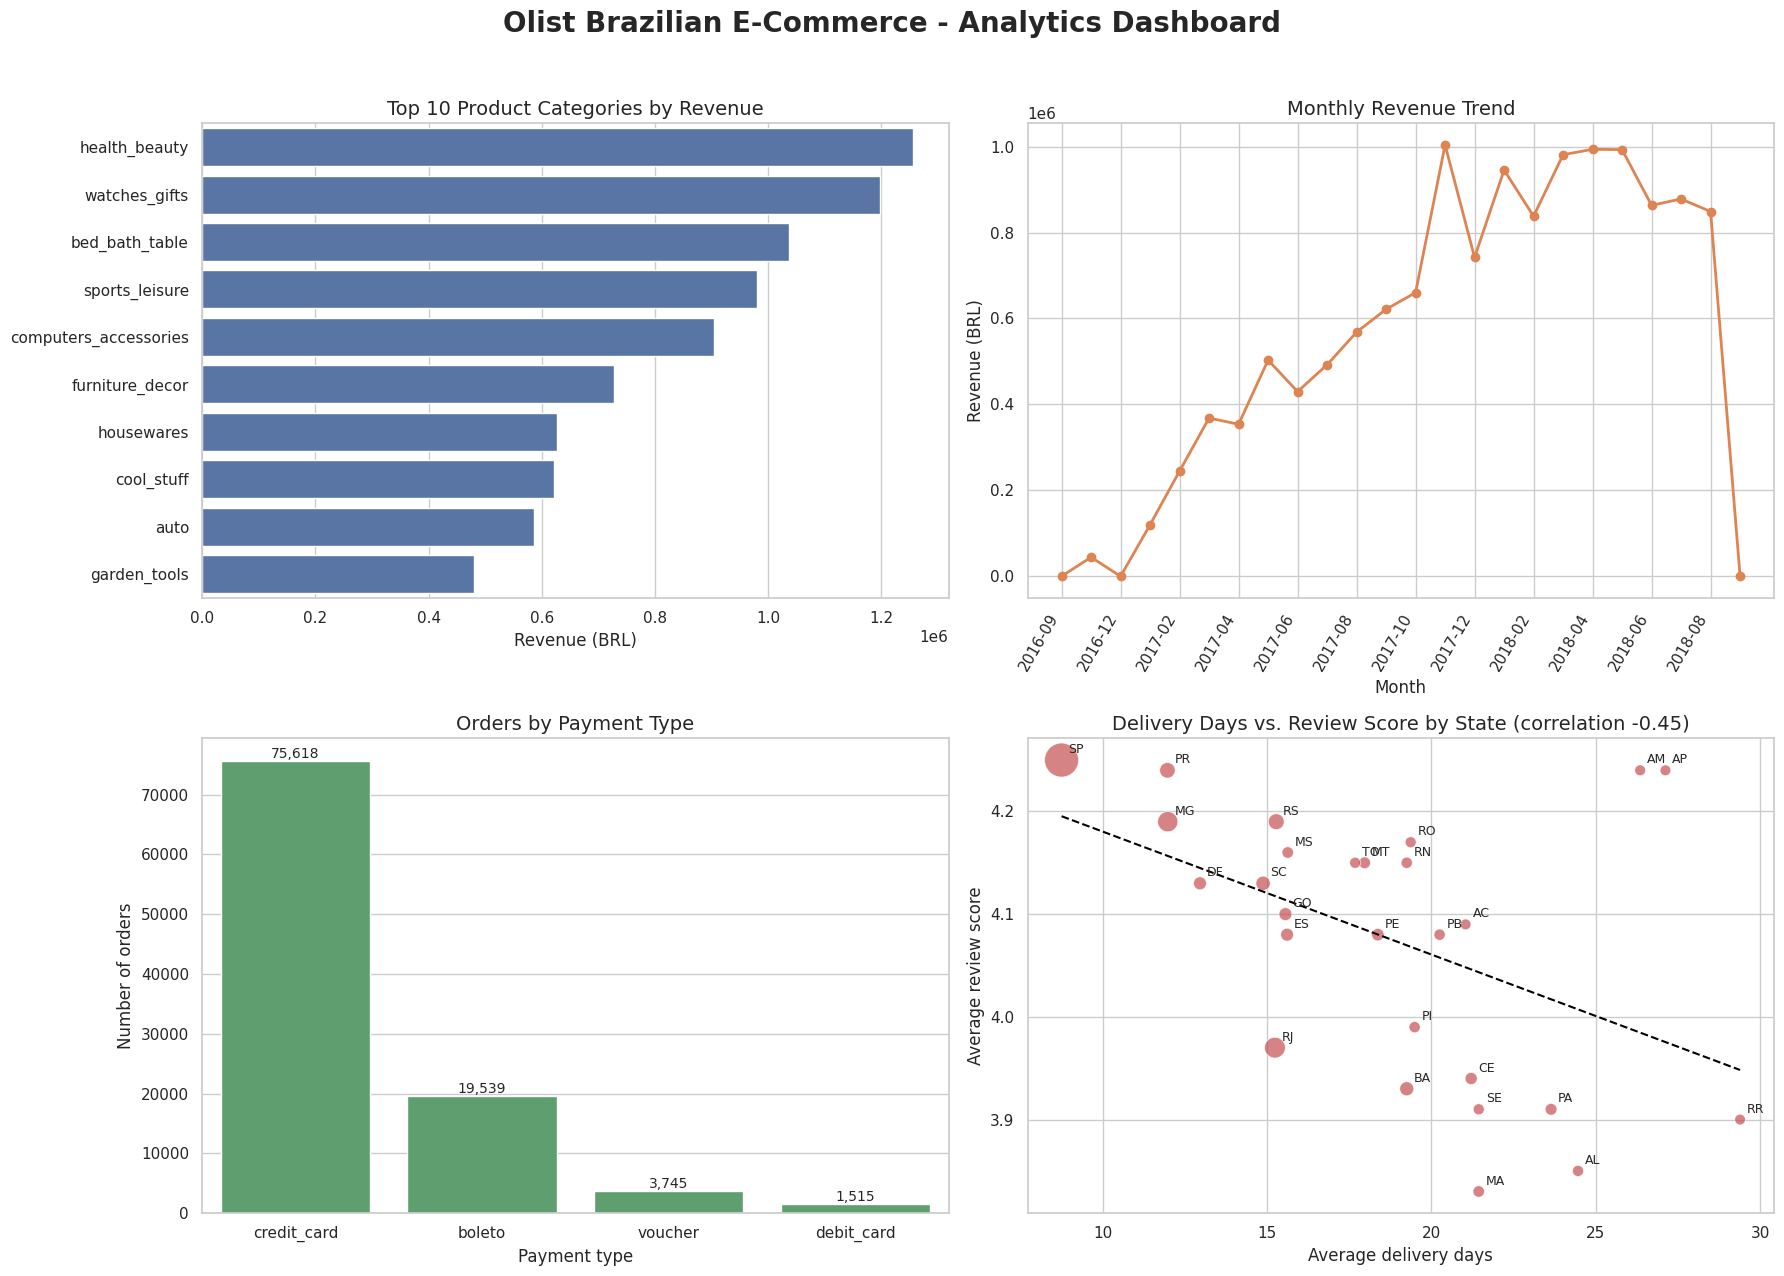

In [0]:
# ==========================================================================================================================================
#                                                   CELL 4 - STEP 5: SPARK SQL ANALYTICS
# ==========================================================================================================================================
# Goal: answer 4 business questions with Spark SQL, print the result tables,
# then draw them as a 2x2 chart and save it as a PNG.

# "os" and "shutil" handle files; numpy and pandas handle small tables and maths;
# matplotlib draws the charts.
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Try to load seaborn (nicer-looking charts). If it is not installed, the code
# falls back to plain Matplotlib so the notebook never crashes.
try:
    import seaborn as sns
    HAS_SEABORN = True
    # Apply a clean white grid style to all charts.
    sns.set_theme(style="whitegrid")
except Exception:
    sns = None
    HAS_SEABORN = False
    print("Note: seaborn is not installed here, so plain Matplotlib will be used for the charts.")

# Where the finished chart image will be saved.
CHART_PATH = "/Volumes/workspace/default/olist_dataset/olist_analytics_charts.png"
# Make printed tables wide enough that they do not wrap onto new lines.
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

# WHY aggregate in Spark before plotting? The unified table has tens of thousands
# of rows and Spark is built to crunch big data in parallel. Matplotlib only
# works on small tables in the notebook's memory. So Spark SQL boils the data
# down to a handful of summary rows, and ONLY those are converted to pandas
# (.toPandas()) and plotted.
print("=" * 70)
print("STEP 4.1 - Query 1: Top 10 product categories by revenue")
print("=" * 70)
# EXPLODE unpacks the per-order category list built in Cell 3 into one row per
# (order, category). We then add up revenue per category, sort from highest to
# lowest, and keep the top 10.

q1 = spark.sql("""
    SELECT cr.category AS category,
           ROUND(SUM(cr.revenue), 2) AS revenue,
           COUNT(DISTINCT u.order_id) AS orders
    FROM olist_unified u
    LATERAL VIEW EXPLODE(u.category_revenues) t AS cr
    GROUP BY cr.category
    ORDER BY revenue DESC
    LIMIT 10
""").toPandas()
print(q1.to_string(index=False))
# Check: the query must return something.
if len(q1) == 0:
    raise Exception("CHECK FAILED: Query 1 returned no rows.")
print(f"CHECK PASSED: Query 1 returned {len(q1)} categories.")

print()
print("=" * 70)
print("STEP 4.2 - Query 2: Monthly revenue trend")
print("=" * 70)
# Group orders by purchase month and add up revenue and count orders.
# Orders without items or a date are skipped because they have no revenue to show.
q2 = spark.sql("""
    SELECT purchase_month,
           ROUND(SUM(total_price), 2) AS revenue,
           COUNT(*) AS orders
    FROM olist_unified
    WHERE total_price IS NOT NULL AND purchase_month IS NOT NULL
    GROUP BY purchase_month
    ORDER BY purchase_month
""").toPandas()
print(q2.to_string(index=False))
if len(q2) == 0:
    raise Exception("CHECK FAILED: Query 2 returned no rows.")
print(f"CHECK PASSED: Query 2 returned {len(q2)} months.")
print("Note: The first and last months in the dataset are partial, so they look small.")

print()
print("=" * 70)
print("STEP 4.3 - Query 3: Payment types")
print("=" * 70)
# EXPLODE unpacks the per-order payment list into one row per (order, payment type).
# Then count how many orders used each type and how much money was paid.
q3 = spark.sql("""
    SELECT p.payment_type AS payment_type,
           COUNT(DISTINCT u.order_id) AS orders,
           ROUND(SUM(p.value), 2) AS total_payment_value,
           ROUND(AVG(p.value), 2) AS avg_payment_value
    FROM olist_unified u
    LATERAL VIEW EXPLODE(u.payment_breakdown) t AS p
    GROUP BY p.payment_type
    ORDER BY orders DESC
""").toPandas()
print(q3.to_string(index=False))
if len(q3) == 0:
    raise Exception("CHECK FAILED: Query 3 returned no rows.")
print(f"CHECK PASSED: Query 3 returned {len(q3)} payment types.")

print()
print("=" * 70)
print("STEP 4.4 - Query 4: Delivery days vs. review score by customer state")
print("=" * 70)
# For each Brazilian state: how many delivered orders, average delivery time and
# average review score. Only orders that were delivered AND reviewed are used,
# otherwise the averages would be based on missing values
q4 = spark.sql("""
    SELECT customer_state,
           COUNT(*) AS delivered_orders,
           ROUND(AVG(delivery_days), 2) AS avg_delivery_days,
           ROUND(AVG(avg_review_score), 2) AS avg_review_score
    FROM olist_unified
    WHERE delivery_days IS NOT NULL
      AND avg_review_score IS NOT NULL
      AND customer_state IS NOT NULL
    GROUP BY customer_state
    ORDER BY avg_delivery_days DESC
""").toPandas()
print(q4.to_string(index=False))
if len(q4) == 0:
    raise Exception("CHECK FAILED: Query 4 returned no rows.")
# Correlation measures how strongly two numbers move together: -1 means one goes
# up as the other goes down, 0 means no relationship, +1 means they rise together.
correlation = float(np.corrcoef(q4["avg_delivery_days"], q4["avg_review_score"])[0, 1])
print(f"CHECK PASSED: Query 4 returned {len(q4)} states.")
print(f"Correlation between average delivery days and average review score across states: {correlation:.3f}")
print("(A negative number means: states with slower delivery tend to give lower review scores.)")

# ==========================================================================================================================================
#                                                          STEP 6: VISUALIZATION 
# ==========================================================================================================================================
print()
print("=" * 70)
print("STEP 4.5 - Building the 2x2 chart")
print("=" * 70)
# Create one big figure containing a 2-by-2 grid of charts, with a main title.
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle("Olist Brazilian E-Commerce - Analytics Dashboard", fontsize=20, fontweight="bold")

# Chart 1: Top 10 categories by revenue 
ax1 = axes[0, 0]
if HAS_SEABORN:
    sns.barplot(data=q1, x="revenue", y="category", color="#4C72B0", ax=ax1)
else:
    ax1.barh(q1["category"], q1["revenue"], color="#4C72B0")
    # Flip the order so the highest-revenue category appears at the top.
    ax1.invert_yaxis()
ax1.set_title("Top 10 Product Categories by Revenue", fontsize=14)
ax1.set_xlabel("Revenue (BRL)")
ax1.set_ylabel("")

# Chart 2: Monthly revenue trend
ax2 = axes[0, 1]
ax2.plot(q2["purchase_month"], q2["revenue"], marker="o", color="#DD8452", linewidth=2)
ax2.set_title("Monthly Revenue Trend", fontsize=14)
ax2.set_xlabel("Month")
ax2.set_ylabel("Revenue (BRL)")
# Show a label on every second month and tilt it, so the labels do not overlap.
tick_positions = list(range(0, len(q2), 2))
ax2.set_xticks(tick_positions)
ax2.set_xticklabels([q2["purchase_month"].iloc[i] for i in tick_positions], rotation=60, ha="right")

# Chart 3: Payment types
ax3 = axes[1, 0]
if HAS_SEABORN:
    sns.barplot(data=q3, x="payment_type", y="orders", color="#55A868", ax=ax3)
else:
    ax3.bar(q3["payment_type"], q3["orders"], color="#55A868")
ax3.set_title("Orders by Payment Type", fontsize=14)
ax3.set_xlabel("Payment type")
ax3.set_ylabel("Number of orders")
# Write the exact order count above each bar.
for i, v in enumerate(q3["orders"]):
    ax3.text(i, v, f"{int(v):,}", ha="center", va="bottom", fontsize=10)

# Chart 4: Delivery days vs review score by state
ax4 = axes[1, 1]
if HAS_SEABORN:
    sns.scatterplot(
        data=q4, x="avg_delivery_days", y="avg_review_score",
        size="delivered_orders", sizes=(60, 600), legend=False,
        color="#C44E52", alpha=0.7, ax=ax4,
    )
else:
    ax4.scatter(q4["avg_delivery_days"], q4["avg_review_score"], s=q4["delivered_orders"] / 20, color="#C44E52", alpha=0.7)
    # Write each state's abbreviation (SP, RJ, ...) next to its dot.
for _, row in q4.iterrows():
    ax4.annotate(row["customer_state"], (row["avg_delivery_days"], row["avg_review_score"]),
                 textcoords="offset points", xytext=(5, 5), fontsize=9)
    # Fit a straight trend line through the dots (slope and intercept) and draw it
# as a dashed black line to show the overall direction of the relationship.
slope, intercept = np.polyfit(q4["avg_delivery_days"], q4["avg_review_score"], 1)
x_line = np.linspace(q4["avg_delivery_days"].min(), q4["avg_delivery_days"].max(), 50)
ax4.plot(x_line, slope * x_line + intercept, color="black", linestyle="--", linewidth=1.5)
ax4.set_title(f"Delivery Days vs. Review Score by State (correlation {correlation:.2f})", fontsize=14)
ax4.set_xlabel("Average delivery days")
ax4.set_ylabel("Average review score")

# Adjust spacing so titles and labels do not overlap or get cut off.
plt.tight_layout(rect=[0, 0, 1, 0.96])
print("CHECK PASSED: The 2x2 chart was built.")

print()
print("=" * 70)
print("STEP 4.6 - Saving the chart as a PNG")
print("=" * 70)
# Save to the temporary /tmp folder first, then copy into the Volume, because
# writing an image straight into a Volume can fail.
local_png = "/tmp/olist_analytics_charts.png"
fig.savefig(local_png, dpi=150, bbox_inches="tight")
shutil.copyfile(local_png, CHART_PATH)
# Check: confirm the file really exists, then print its size
if not os.path.exists(CHART_PATH):
    raise Exception("CHECK FAILED: The PNG file was not found after saving.")
size_kb = os.path.getsize(CHART_PATH) / 1024
print(f"  Saved to: {CHART_PATH}")
print(f"  File size: {size_kb:,.1f} KB")
print("CHECK PASSED: PNG chart saved to your volume.")
# Display the chart inside the notebook as well.
plt.show()